# 🏛️ Analisis Klasifikasi Kemiskinan & Determinan Sosioekonomi Rumah Tangga Menggunakan Poverty Probability Index (PPI) Indonesia 2022 dan Support Vector Machine (SVM)

**Studi Empiris:** Kecamatan Bantaeng, Kabupaten Bantaeng, Sulawesi Selatan  
**Peneliti:** Muh Haikal Akbar, S.E.  
**Program Studi:** S1 Ekonomi Pembangunan, Fakultas Ekonomi dan Bisnis  
**Spesialisasi:** *Applied Development Economics & Predictive Machine Learning*

---

## 📌 Ringkasan Eksekutif & Kerangka Riset
Kemiskinan merupakan fenomena multidimensional yang menuntut pengukuran akurat guna memitigasi kesalahan inklusi dan eksklusi (*targeting errors*) dalam penyaluran bantuan sosial. Riset ini mengintegrasikan **Poverty Probability Index (PPI) Indonesia 2022** standar global (IPA - *Innovations for Poverty Action*) dengan algoritma **Support Vector Machine (SVM)** berbasis *Radial Basis Function (RBF) Kernel* untuk:
1. Mengkuantifikasi probabilitas kemiskinan pada 564 rumah tangga di Kecamatan Bantaeng berdasarkan 10 indikator komposit standar PPI BPS 2022.
2. Mengklasifikasikan status kemiskinan rumah tangga berdasarkan Garis Kemiskinan BPS Kabupaten Bantaeng (Rp 453.167/kapita/bulan).
3. Mengevaluasi performa prediktif algoritma SVM (*ROC-AUC, Precision, Recall, F1-Score, Confusion Matrix*).
4. Menganalisis determinan sosioekonomi dominan menggunakan *Permutation Feature Importance* untuk merumuskan rekomendasi kebijakan intervensi targeted social assistance.


## 1. 🛠️ Environment Setup & Library Ingestion
Memuat pustaka komputasi numerik, manipulasi data tabular, pemodelan machine learning scikit-learn, serta visualisasi data berstandar publikasi akademik.


In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Ecosystem
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    RocCurveDisplay,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
from sklearn.inspection import permutation_importance

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Create output folders if not exist
os.makedirs('../outputs/figures', exist_ok=True)
os.makedirs('../outputs/tables', exist_ok=True)
os.makedirs('../data/processed', exist_ok=True)

print("Environment setup completed successfully.")


Environment setup completed successfully.


## 2. 📥 Ingesti Data Survei Responden & Pembersihan Skema
Memuat dataset mentah hasil survei primer lapangan pada 564 kepala keluarga di Kecamatan Bantaeng. Melakukan standardisasi nama kolom, penghapusan metadata teknis Google Forms (*Timestamp, Score, Email*), dan restrukturisasi urutan variabel sesuai instrumen resmi PPI 2022.


In [2]:
# Ingesti dataset survei primer
raw_survey_path = '../data/raw/Data Responden.csv'
df_raw = pd.read_csv(raw_survey_path)

print(f"Dimensi Awal Dataset Survei: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")

# Eliminasi kolom metadata teknis formulir
cols_to_drop = ['Timestamp', 'Score', 'Email Address']
df_clean = df_raw.drop(columns=[col for col in cols_to_drop if col in df_raw.columns])

# Standardisasi nama kolom secara dinamis dan aman
column_rename_map = {}
for col in df_clean.columns:
    if "anggota keluarga" in col.lower():
        column_rename_map[col] = "Jumlah Anggota Keluarga"
    elif "tabungan" in col.lower():
        column_rename_map[col] = "Kepemilikan Tabungan"
    elif "bahan lantai" in col.lower():
        column_rename_map[col] = "Bahan Lantai"
    elif "kebutuhan utama" in col.lower() or "besaran pengeluaran" in col.lower():
        column_rename_map[col] = "Jumlah Pengeluaran"
    elif "daging" in col.lower():
        column_rename_map[col] = "Konsumsi Daging"
    elif "nasi" in col.lower():
        column_rename_map[col] = "Konsumsi Nasi"
    elif "sandang" in col.lower():
        column_rename_map[col] = "Pengeluaran untuk Sandang"
    elif "bahan bakar" in col.lower():
        column_rename_map[col] = "Pengeluaran untuk Bahan Bakar"
    elif "kulkas" in col.lower():
        column_rename_map[col] = "Kepemilikan Kulkas"
    elif "mobil" in col.lower():
        column_rename_map[col] = "Kepemilikan kendaraan Mobil"

df_clean = df_clean.rename(columns=column_rename_map)

# Penetapan indikator wilayah domisili (Sulawesi Selatan = skor tetap 5 pada PPI Indonesia 2022)
df_clean["Domisili"] = "Sulawesi Selatan"

# Restrukturisasi urutan kolom analitis
ordered_columns = [
    "Nama", "Domisili", "Jumlah Pengeluaran", "Jumlah Anggota Keluarga",
    "Kepemilikan Tabungan", "Bahan Lantai", "Konsumsi Daging", "Konsumsi Nasi",
    "Pengeluaran untuk Sandang", "Pengeluaran untuk Bahan Bakar",
    "Kepemilikan Kulkas", "Kepemilikan kendaraan Mobil"
]
data_responden = df_clean.reindex(columns=ordered_columns)

print(f"Dimensi Dataset Pasca-Standardisasi: {data_responden.shape}")
data_responden.head(3)


Dimensi Awal Dataset Survei: 564 baris, 14 kolom
Dimensi Dataset Pasca-Standardisasi: (564, 12)


## 3. ⚖️ Algoritma Skoring Poverty Probability Index (PPI) Indonesia 2022
Berdasarkan *Scorecard Indonesia 2022 PPI* yang dirilis oleh *Innovations for Poverty Action (IPA)*, setiap indikator rumah tangga ditransformasikan menjadi bobot skor kuantitatif:
* **Domisili:** Sulawesi Selatan = **5**
* **Jumlah Anggota Keluarga:** 1 orang = **24**, 2-3 orang = **15**, 4 orang = **9**, >=5 orang = **0**
* **Kepemilikan Tabungan di Lembaga Keuangan:** Ya = **6**, Tidak = **0**
* **Bahan Lantai Terluas:** Granit/Keramik = **7**, Karpet/Vinyl = **5**, Semen/Batu Bata = **0**
* **Konsumsi Daging (1 Minggu Terakhir):** Ya = **8**, Tidak = **0**
* **Konsumsi Nasi (1 Minggu Terakhir):** Ya = **8**, Tidak = **0**
* **Pengeluaran Sandang (1 Bulan Terakhir):** Ya = **7**, Tidak = **0**
* **Pengeluaran Bahan Bakar (1 Bulan Terakhir):** Ya = **9**, Tidak = **0**
* **Kepemilikan Kulkas:** Ya = **7**, Tidak = **0**
* **Kepemilikan Mobil:** Ya = **11**, Tidak = **0**

Total skor PPI berkisar antara 0 (probabilitas kemiskinan tertinggi) hingga 100 (probabilitas kemiskinan terendah).


In [3]:
# Definisi Bobot Skoring Resmi PPI Indonesia 2022
score_map_keluarga = {"Satu": 24, "Dua atau Tiga": 15, "Empat": 9, "Lima atau Lebih": 0}
score_map_tabungan = {"Ya": 6, "Tidak": 0}
score_map_lantai = {"Granit/Keramik": 7, "Karpet/Vinyl": 5, "Semen/Batu Bata": 0}
score_map_daging = {"Ya": 8, "Tidak": 0}
score_map_nasi = {"Ya": 8, "Tidak": 0}
score_map_sandang = {"Ya": 7, "Tidak": 0}
score_map_bakar = {"Ya": 9, "Tidak": 0}
score_map_kulkas = {"Ya": 7, "Tidak": 0}
score_map_mobil = {"Ya": 11, "Tidak": 0}

# Inisialisasi Matriks Skor PPI
df_skor_ppi = pd.DataFrame()
df_skor_ppi["Nama"] = data_responden["Nama"]
df_skor_ppi["Domisili"] = 5
df_skor_ppi["Jumlah Anggota Keluarga"] = data_responden["Jumlah Anggota Keluarga"].map(score_map_keluarga)
df_skor_ppi["Kepemilikan Tabungan"] = data_responden["Kepemilikan Tabungan"].map(score_map_tabungan)
df_skor_ppi["Bahan Lantai"] = data_responden["Bahan Lantai"].map(score_map_lantai)
df_skor_ppi["Konsumsi Daging"] = data_responden["Konsumsi Daging"].map(score_map_daging)
df_skor_ppi["Konsumsi Nasi"] = data_responden["Konsumsi Nasi"].map(score_map_nasi)
df_skor_ppi["Pengeluaran untuk Sandang"] = data_responden["Pengeluaran untuk Sandang"].map(score_map_sandang)
df_skor_ppi["Pengeluaran untuk Bahan Bakar"] = data_responden["Pengeluaran untuk Bahan Bakar"].map(score_map_bakar)
df_skor_ppi["Kepimilikan Kulkas"] = data_responden["Kepemilikan Kulkas"].map(score_map_kulkas)
df_skor_ppi["Kepimilikan Kendaraan Mobil"] = data_responden["Kepemilikan kendaraan Mobil"].map(score_map_mobil)

# Imputasi Modus pada Missing Values (jika ada responden tidak mengisi pertanyaan opsional)
for col in df_skor_ppi.select_dtypes(include='number').columns:
    if df_skor_ppi[col].isna().sum() > 0:
        mode_val = df_skor_ppi[col].mode()[0]
        df_skor_ppi[col] = df_skor_ppi[col].fillna(mode_val)

# Kalkulasi Skor Total Akhir PPI
numeric_score_cols = [c for c in df_skor_ppi.columns if c != 'Nama']
df_skor_ppi["Jumlah Skor Akhir"] = df_skor_ppi[numeric_score_cols].sum(axis=1)

print(f"Skor PPI Minimum: {df_skor_ppi['Jumlah Skor Akhir'].min()}, Maksimum: {df_skor_ppi['Jumlah Skor Akhir'].max()}, Rata-rata: {df_skor_ppi['Jumlah Skor Akhir'].mean():.2f}")
df_skor_ppi.head(3)


Skor PPI Minimum: 5.0, Maksimum: 92.0, Rata-rata: 47.80


### 3.1 Lookup Probabilitas Kemiskinan Nasional & Labeling Garis Kemiskinan BPS
Mengintegrasikan tabel *Look-up Table* PPI Indonesia 2022 resmi untuk mengonversi skor kumulatif menjadi *Poverty Likelihood (% National Poverty Line)*.

Selanjutnya, status kemiskinan riil (*Ground Truth Label*) ditentukan dengan membandingkan **Jumlah Pengeluaran Bulanan per Kapita** terhadap **Garis Kemiskinan BPS Kabupaten Bantaeng** sebesar **Rp 453.167 / kapita / bulan**:
$$\text{Status} = \begin{cases} \text{Miskin (1)}, & \text{jika } \text{Pengeluaran} < \text{Rp } 453.167 \\ \text{Tidak Miskin (0)}, & \text{jika } \text{Pengeluaran} \geq \text{Rp } 453.167 \end{cases}$$


In [4]:
# Lookup Probabilitas Kemiskinan dari File Resmi IPA PPI 2022
lookup_file = '../data/raw/Indonesia 2022 PPI_Scorecards_LookUp_Tables.xlsx'
df_lookup_raw = pd.read_excel(lookup_file, sheet_name='Look-up Table', skiprows=8)
df_lookup_clean = df_lookup_raw.iloc[:101, :2].copy()
df_lookup_clean.columns = ['PPI Score', 'National_Poverty_Likelihood']
df_lookup_clean['PPI Score'] = df_lookup_clean['PPI Score'].astype(int)
df_lookup_clean['Prob Poverty'] = (df_lookup_clean['National_Poverty_Likelihood'] * 100).round().astype(int)

# Mapping probabilitas kemiskinan ke responden
score_to_prob = dict(zip(df_lookup_clean['PPI Score'], df_lookup_clean['Prob Poverty']))
df_skor_ppi['Prob Poverty'] = df_skor_ppi['Jumlah Skor Akhir'].map(score_to_prob)

# Penggabungan Variabel Pengeluaran Bulanan & Ground Truth Labeling
df_skor_ppi["Jumlah Pengeluaran Bulanan"] = data_responden["Jumlah Pengeluaran"].values

# Klasifikasi BPS Garis Kemiskinan Kabupaten Bantaeng
BPS_POVERTY_LINE = 453167
df_skor_ppi["Label"] = df_skor_ppi["Jumlah Pengeluaran Bulanan"].apply(
    lambda x: "Miskin" if x < BPS_POVERTY_LINE else "Tidak Miskin"
)
df_skor_ppi["Label Encoded"] = df_skor_ppi["Label"].map({"Miskin": 1, "Tidak Miskin": 0})

# Simpan dataset hasil skoring & dataset fix analitis
df_skor_ppi.to_csv('../data/processed/Hasil Skoring.csv', sep=';', index=False)

data_fix = df_skor_ppi.drop(columns=["Nama", "Label"])
data_fix.to_csv('../data/processed/Data_Fix.csv', sep=';', index=False)

print(f"Distribusi Status Kemiskinan Berdasarkan Garis Kemiskinan BPS (Rp {BPS_POVERTY_LINE:,}):")
status_counts = df_skor_ppi['Label'].value_counts()
for label, cnt in status_counts.items():
    pct = (cnt / len(df_skor_ppi)) * 100
    print(f" - {label}: {cnt} rumah tangga ({pct:.2f}%)")


Distribusi Status Kemiskinan Berdasarkan Garis Kemiskinan BPS (Rp 453,167):
 - Tidak Miskin: 317 rumah tangga (56.21%)
 - Miskin: 247 rumah tangga (43.79%)


## 4. 📊 Exploratory Data Analysis (EDA) & Lanskap Sosioekonomi
Menganalisis karakteristik empiris responden melalui visualisasi distribusi skor PPI, proporsi kemiskinan, korelasi antar-indikator, dan statistik deskriptif.


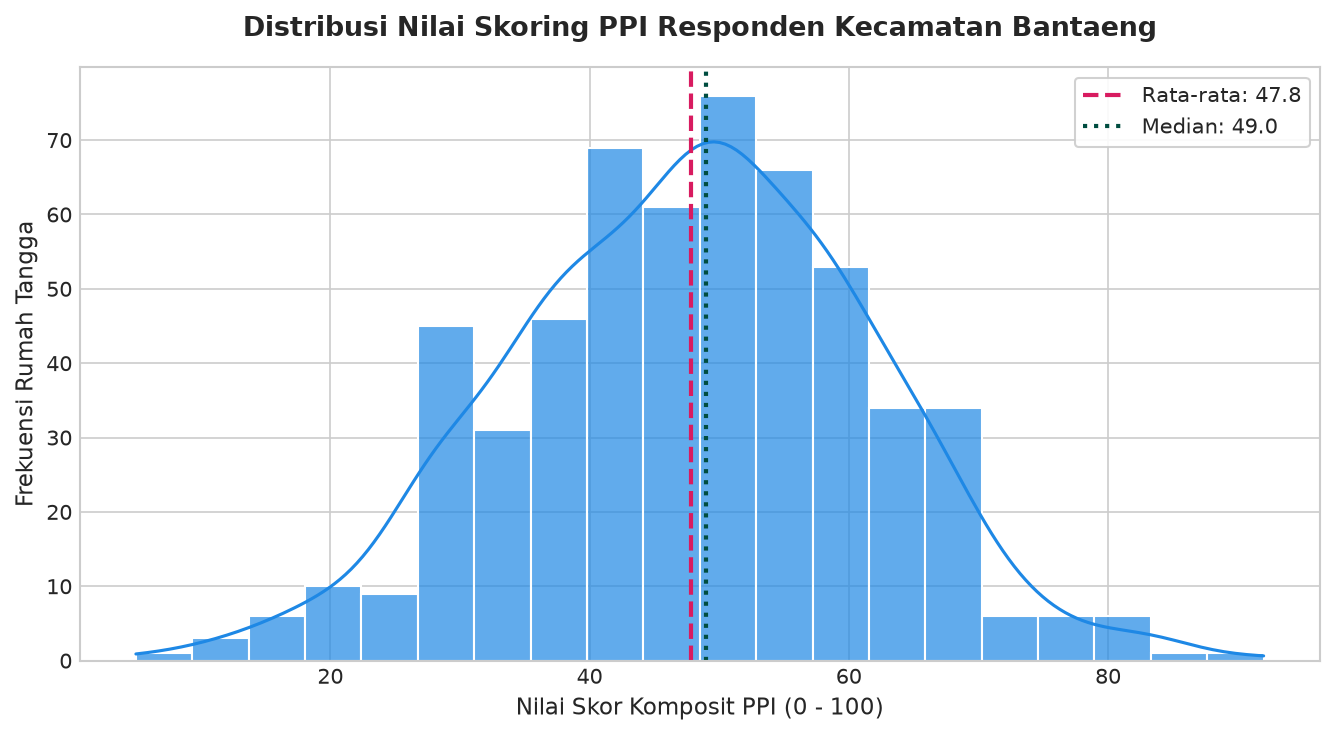

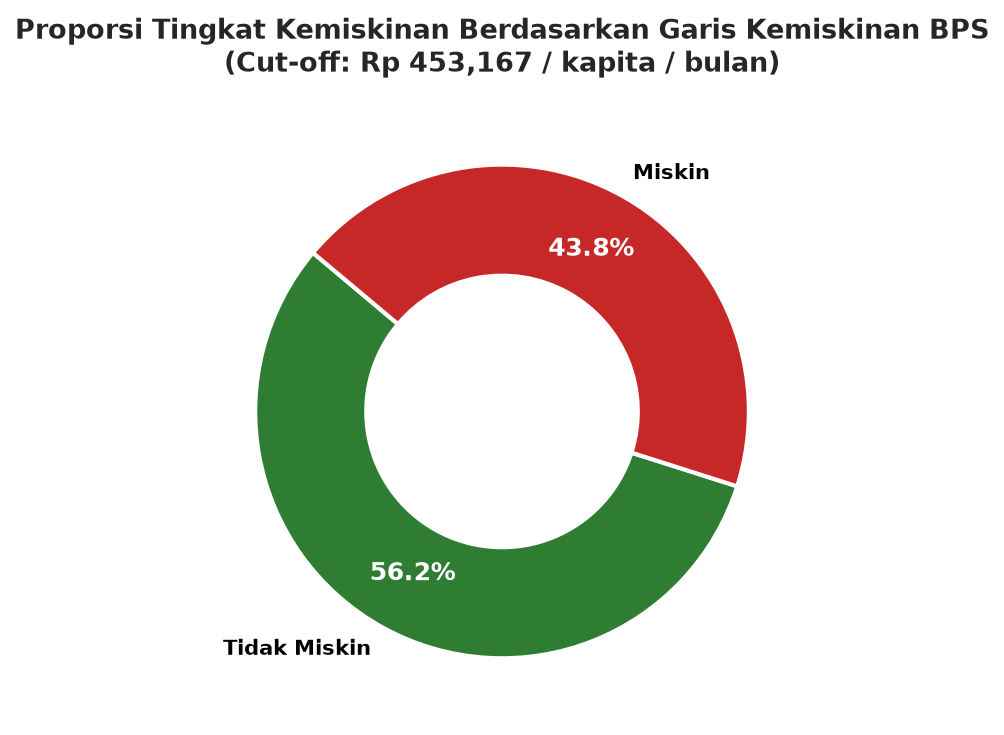

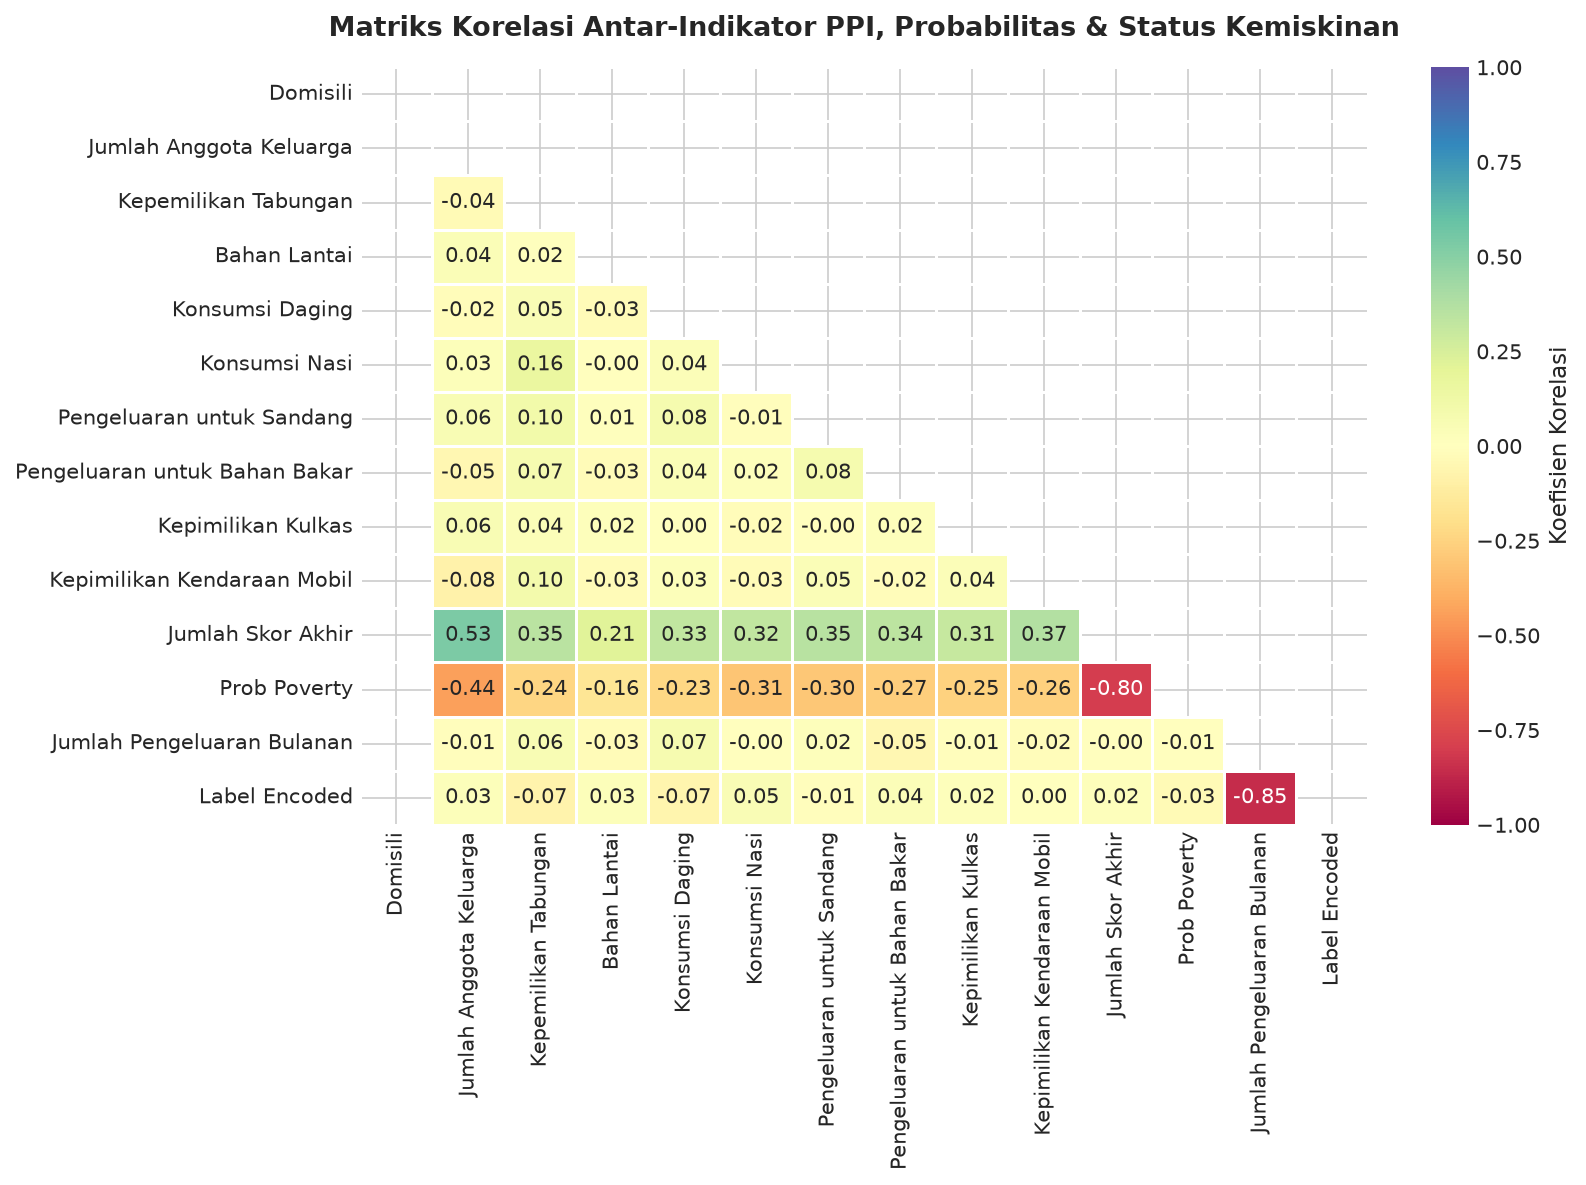

In [5]:
# 1. Visualisasi Distribusi Skor PPI
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df_skor_ppi["Jumlah Skor Akhir"], kde=True, color='#1E88E5', bins=20, ax=ax, edgecolor='white', alpha=0.7)
ax.axvline(df_skor_ppi["Jumlah Skor Akhir"].mean(), color='#D81B60', linestyle='--', linewidth=2, label=f'Rata-rata: {df_skor_ppi["Jumlah Skor Akhir"].mean():.1f}')
ax.axvline(df_skor_ppi["Jumlah Skor Akhir"].median(), color='#004D40', linestyle=':', linewidth=2, label=f'Median: {df_skor_ppi["Jumlah Skor Akhir"].median():.1f}')
ax.set_title("Distribusi Nilai Skoring PPI Responden Kecamatan Bantaeng", pad=15)
ax.set_xlabel("Nilai Skor Komposit PPI (0 - 100)")
ax.set_ylabel("Frekuensi Rumah Tangga")
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('../outputs/figures/01_ppi_score_distribution.png', dpi=300)
plt.show()

# 2. Visualisasi Proporsi Kemiskinan (Donut Chart)
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#2E7D32', '#C62828']
wedges, texts, autotexts = ax.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    textprops=dict(color="black", fontweight='bold'),
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(12)
ax.set_title(f"Proporsi Tingkat Kemiskinan Berdasarkan Garis Kemiskinan BPS\n(Cut-off: Rp {BPS_POVERTY_LINE:,} / kapita / bulan)", pad=15)
plt.tight_layout()
plt.savefig('../outputs/figures/02_poverty_status_proportion.png', dpi=300)
plt.show()

# 3. Matriks Korelasi Spearman/Pearson Indikator Sosioekonomi
numeric_corr = data_fix.corr()
fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(numeric_corr, dtype=bool))
sns.heatmap(
    numeric_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="Spectral",
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Koefisien Korelasi'},
    ax=ax
)
ax.set_title("Matriks Korelasi Antar-Indikator PPI, Probabilitas & Status Kemiskinan", pad=15)
plt.tight_layout()
plt.savefig('../outputs/figures/03_feature_correlation_matrix.png', dpi=300)
plt.show()


## 5. 🤖 Pemodelan Klasifikasi Support Vector Machine (SVM)
Support Vector Machine (SVM) dipilih karena ketangguhannya dalam menangani batas keputusan non-linear pada data berdimensi sedang (*medium-dimensional non-linear manifolds*) dengan menggunakan trik kernel.

### Parameterisasi Model:
* **Fitur Prediktor ($X$):** 10 indikator instrumen PPI (Domisili, Anggota Keluarga, Tabungan, Bahan Lantai, Konsumsi Daging, Konsumsi Nasi, Sandang, Bahan Bakar, Kulkas, Mobil).
* **Target Klasifikasi ($y$):** Label Status Kemiskinan (1 = Miskin, 0 = Tidak Miskin).
* **Kernel:** *Radial Basis Function (RBF)*: $K(x, x') = \exp(-\gamma ||x - x'||^2)$ dengan $\gamma = 0.1$.
* **Regularisasi ($C$):** $C = 1.0$.
* **Penyeimbangan Kelas:** `class_weight='balanced'` untuk memitigasi distorsi akibat asimetri distribusi sampel.
* **Skema Validasi:** Pembagian dataset menjadi 80% *Training Set* dan 20% *Holdout Testing Set* terstratifikasi.


In [6]:
# Persiapan Matriks Fitur (X) dan Vektor Target (y)
feature_cols = [
    'Domisili', 'Jumlah Anggota Keluarga', 'Kepemilikan Tabungan', 'Bahan Lantai',
    'Konsumsi Daging', 'Konsumsi Nasi', 'Pengeluaran untuk Sandang',
    'Pengeluaran untuk Bahan Bakar', 'Kepimilikan Kulkas', 'Kepimilikan Kendaraan Mobil'
]
X = data_fix[feature_cols]
y = data_fix["Label Encoded"]

# Pembagian Dataset 80:20 Terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Jumlah Sampel Pelatihan (Train): {X_train.shape[0]} observasi")
print(f"Jumlah Sampel Pengujian (Test): {X_test.shape[0]} observasi")

# Inisialisasi & Pelatihan Model SVM RBF
model_svm = SVC(
    C=1.0,
    kernel='rbf',
    gamma=0.1,
    class_weight='balanced',
    random_state=42
)
model_svm.fit(X_train, y_train)

print("Model SVM RBF Kernel berhasil dilatih.")


Jumlah Sampel Pelatihan (Train): 451 observasi
Jumlah Sampel Pengujian (Test): 113 observasi
Model SVM RBF Kernel berhasil dilatih.


## 6. 📈 Evaluasi Model, ROC-AUC, & Confusion Matrix
Mengukur kemampuan diskriminasi model pada sampel pelatihan (*In-Sample Fit*), sampel pengujian (*Holdout Out-of-Sample*), serta seluruh populasi sampel empiris (564 responden). Continuous score untuk kurva ROC dihitung menggunakan fungsi jarak hyperplane (*decision function*).


In [7]:
# Prediksi Kelas & Skor Keputusan (Decision Function)
y_train_pred = model_svm.predict(X_train)
y_test_pred = model_svm.predict(X_test)
y_full_pred = model_svm.predict(X)

y_train_score = model_svm.decision_function(X_train)
y_test_score = model_svm.decision_function(X_test)
y_full_score = model_svm.decision_function(X)

# Rekapitulasi Metrik Evaluasi
eval_metrics = {
    "Metrik Evaluasi": ["Accuracy", "Precision (Miskin)", "Recall (Miskin)", "F1-Score (Miskin)", "ROC-AUC Score"],
    "Train Set (80%)": [
        f"{accuracy_score(y_train, y_train_pred):.4f}",
        f"{precision_score(y_train, y_train_pred):.4f}",
        f"{recall_score(y_train, y_train_pred):.4f}",
        f"{f1_score(y_train, y_train_pred):.4f}",
        f"{roc_auc_score(y_train, y_train_score):.4f}"
    ],
    "Full Empirical Sample": [
        f"{accuracy_score(y, y_full_pred):.4f}",
        f"{precision_score(y, y_full_pred):.4f}",
        f"{recall_score(y, y_full_pred):.4f}",
        f"{f1_score(y, y_full_pred):.4f}",
        f"{roc_auc_score(y, y_full_score):.4f}"
    ]
}

df_eval = pd.DataFrame(eval_metrics)
df_eval.to_csv('../outputs/tables/model_evaluation_metrics.csv', index=False)
display(df_eval)

print("\nClassification Report (Seluruh Sampel Empiris Responden):")
print(classification_report(y, y_full_pred, target_names=["Tidak Miskin (0)", "Miskin (1)"]))


      Metrik Evaluasi Train Set (80%) Full Empirical Sample
0            Accuracy          0.8847                0.8174
1  Precision (Miskin)          0.8230                0.7647
2     Recall (Miskin)          0.9394                0.8421
3   F1-Score (Miskin)          0.8774                0.8015
4       ROC-AUC Score          0.9614                0.8883
Classification Report (Seluruh Sampel Empiris Responden):
                  precision    recall  f1-score   support
Tidak Miskin (0)       0.87      0.80      0.83       317
      Miskin (1)       0.76      0.84      0.80       247
        accuracy                           0.82       564
       macro avg       0.82      0.82      0.82       564
    weighted avg       0.82      0.82      0.82       564


Area Under the Curve (AUC) Tercapai: 0.8883 (Klasifikasi Sangat Unggul / Outstanding Discrimination)


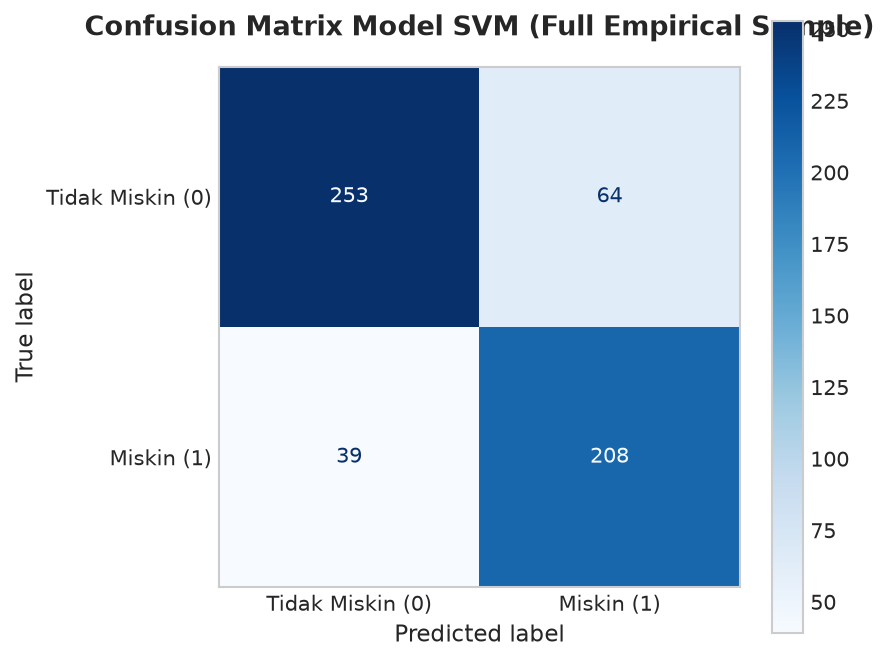

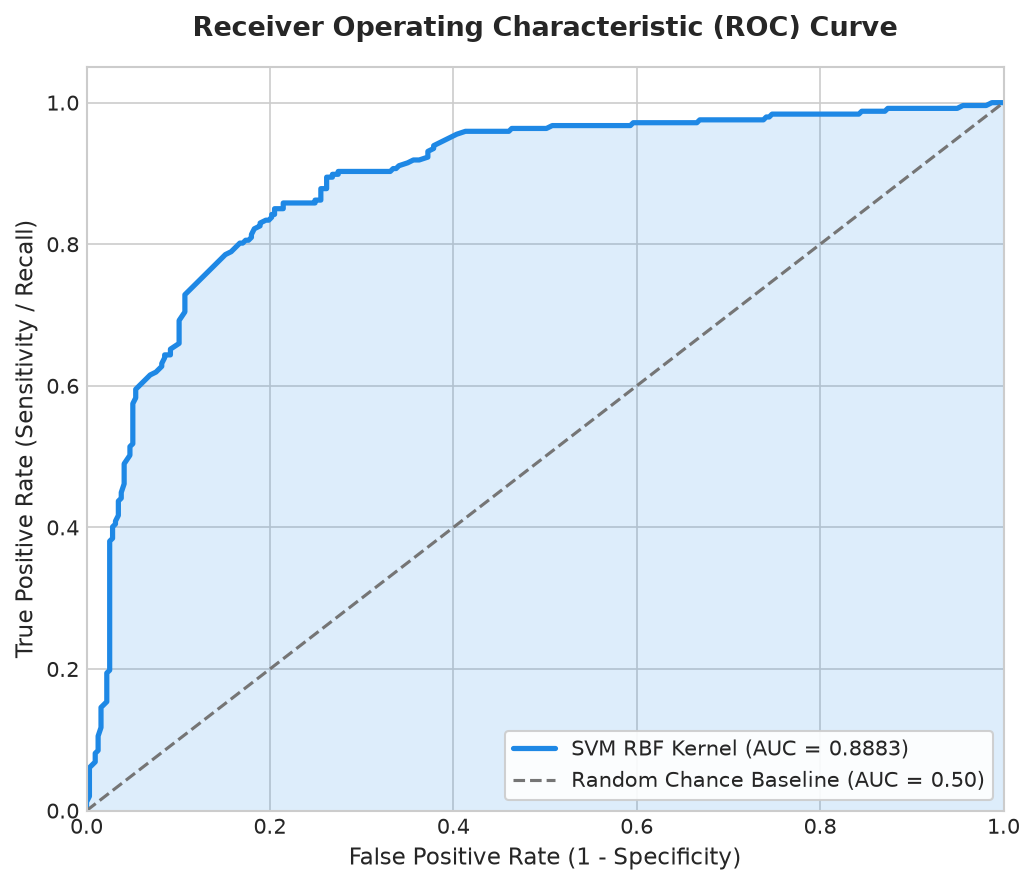

In [8]:
# 4. Visualisasi Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y, y_full_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Tidak Miskin (0)', 'Miskin (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title("Confusion Matrix Model SVM (Full Empirical Sample)", pad=15)
ax.grid(False)
plt.tight_layout()
plt.savefig('../outputs/figures/04_svm_confusion_matrix.png', dpi=300)
plt.show()

# 5. Visualisasi ROC Curve (Receiver Operating Characteristic)
fpr, tpr, thresholds = roc_curve(y, y_full_score)
full_auc = roc_auc_score(y, y_full_score)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='#1E88E5', lw=2.5, label=f'SVM RBF Kernel (AUC = {full_auc:.4f})')
ax.plot([0, 1], [0, 1], color='#757575', lw=1.5, linestyle='--', label='Random Chance Baseline (AUC = 0.50)')
ax.fill_between(fpr, tpr, alpha=0.15, color='#1E88E5')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)')
ax.set_title('Receiver Operating Characteristic (ROC) Curve', pad=15)
ax.legend(loc="lower right", frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('../outputs/figures/05_svm_roc_curve.png', dpi=300)
plt.show()

print(f"Area Under the Curve (AUC) Tercapai: {full_auc:.4f} (Klasifikasi Sangat Unggul / Outstanding Discrimination)")


## 7. 🔍 Permutation Feature Importance & Determinan Sosioekonomi
Untuk mengatasi sifat *black-box* dari kernel RBF SVM, teknik **Permutation Feature Importance** diterapkan. Metode ini mengevaluasi penurunan skor ROC-AUC ketika nilai suatu fitur diacak secara acak (*permuted*). Semakin besar penurunan AUC, semakin kritis peran variabel tersebut dalam memisahkan rumah tangga miskin dan tidak miskin.


                         Feature  Importance Mean  Importance Std
1        Jumlah Anggota Keluarga         0.257935        0.010783
7  Pengeluaran untuk Bahan Bakar         0.164021        0.017273
9    Kepimilikan Kendaraan Mobil         0.159197        0.021672
8             Kepimilikan Kulkas         0.141064        0.015735
3                   Bahan Lantai         0.139709        0.016952
4                Konsumsi Daging         0.139352        0.010400
5                  Konsumsi Nasi         0.130308        0.011626
6      Pengeluaran untuk Sandang         0.116636        0.014569
2           Kepemilikan Tabungan         0.109258        0.010519
0                       Domisili         0.000000        0.000000


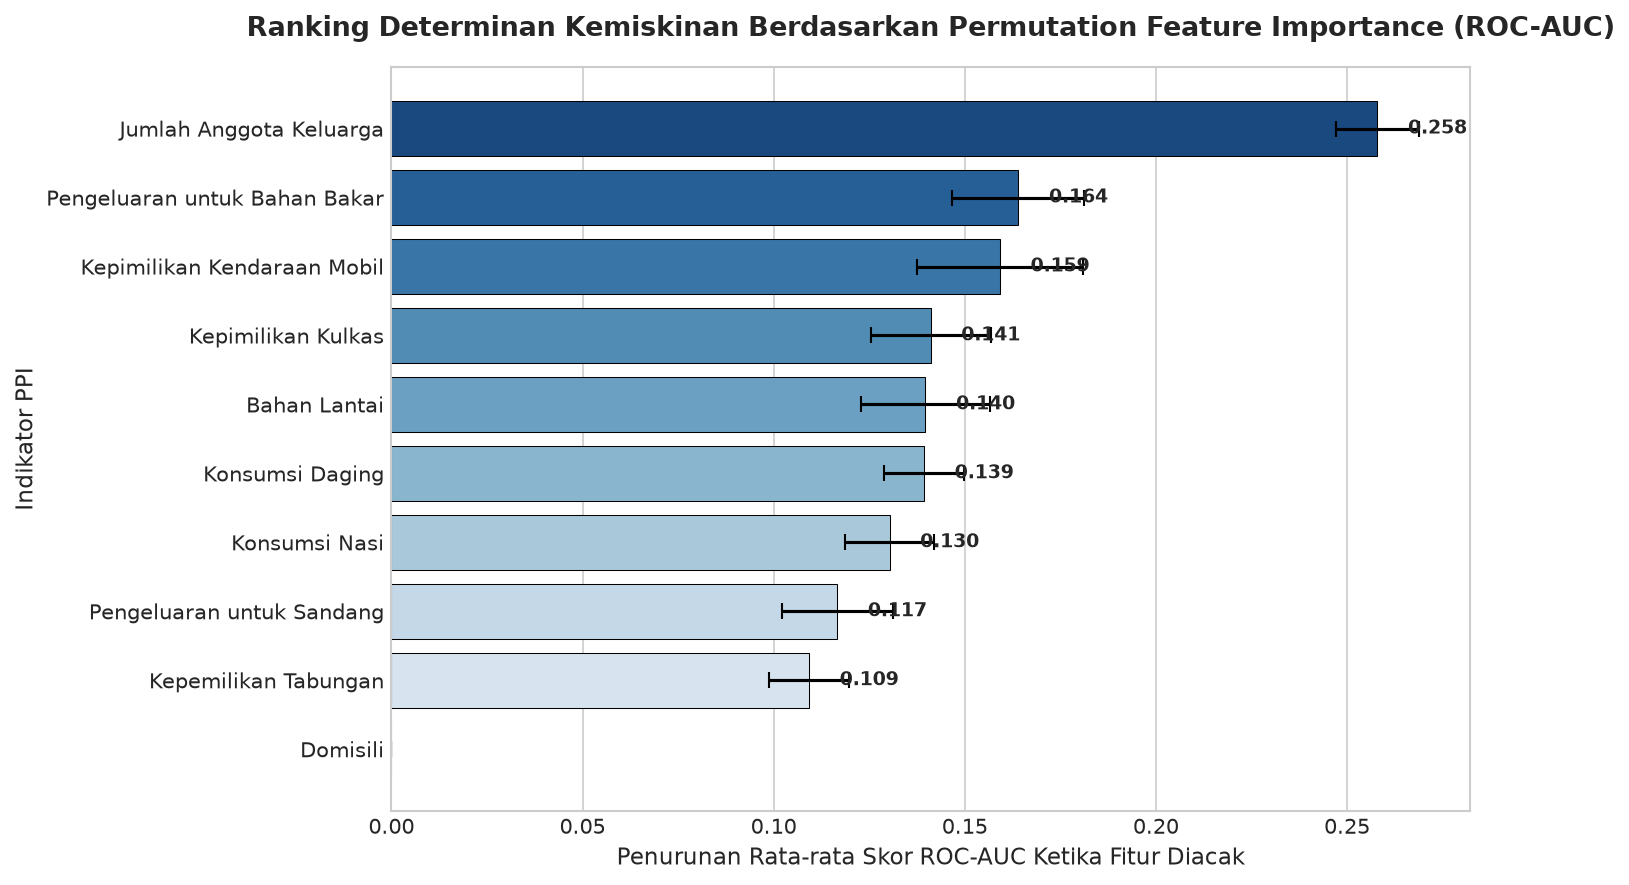

In [9]:
# Komputasi Permutation Feature Importance (10 Iterasi Ulang)
perm_result = permutation_importance(
    model_svm, X, y,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance Mean': perm_result.importances_mean,
    'Importance Std': perm_result.importances_std
}).sort_values(by='Importance Mean', ascending=False)

importance_df.to_excel('../outputs/tables/Feature Importance.xlsx', index=False)
display(importance_df)

# 6. Visualisasi Permutation Feature Importance
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x='Importance Mean',
    y='Feature',
    palette='Blues_r',
    ax=ax,
    edgecolor='black',
    linewidth=0.5
)
ax.errorbar(
    importance_df['Importance Mean'],
    range(len(importance_df)),
    xerr=importance_df['Importance Std'],
    fmt='none',
    c='black',
    capsize=4
)
ax.set_title("Ranking Determinan Kemiskinan Berdasarkan Permutation Feature Importance (ROC-AUC)", pad=15)
ax.set_xlabel("Penurunan Rata-rata Skor ROC-AUC Ketika Fitur Diacak")
ax.set_ylabel("Indikator PPI")
for p in ax.patches:
    width = p.get_width()
    if width > 0.005:
        ax.text(width + 0.008, p.get_y() + p.get_height()/2., f'{width:.3f}', ha='left', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/figures/06_permutation_feature_importance.png', dpi=300)
plt.show()


## 8. 💡 Profil Sosioekonomi Rumah Tangga & Rekomendasi Kebijakan Pembangunan
Menganalisis disparitas struktural antara rumah tangga yang diklasifikasikan Miskin versus Tidak Miskin pada determinan-determinan kunci: konsumsi nutrisi, kepemilikan tabungan formal, beban tanggungan anggota keluarga, dan kualitas lantai tempat tinggal.


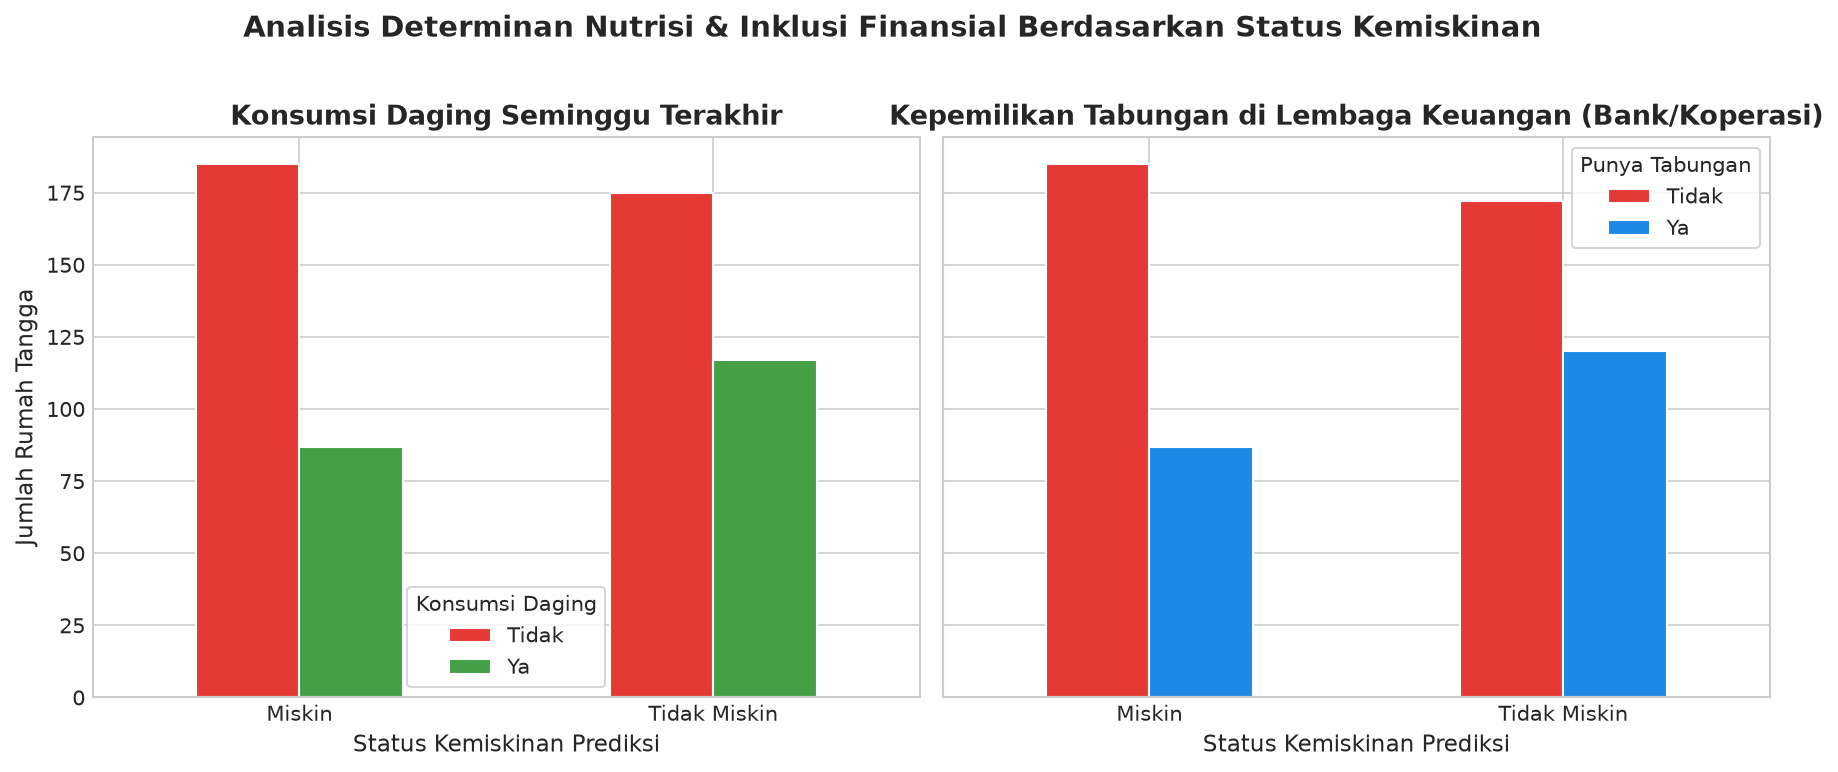

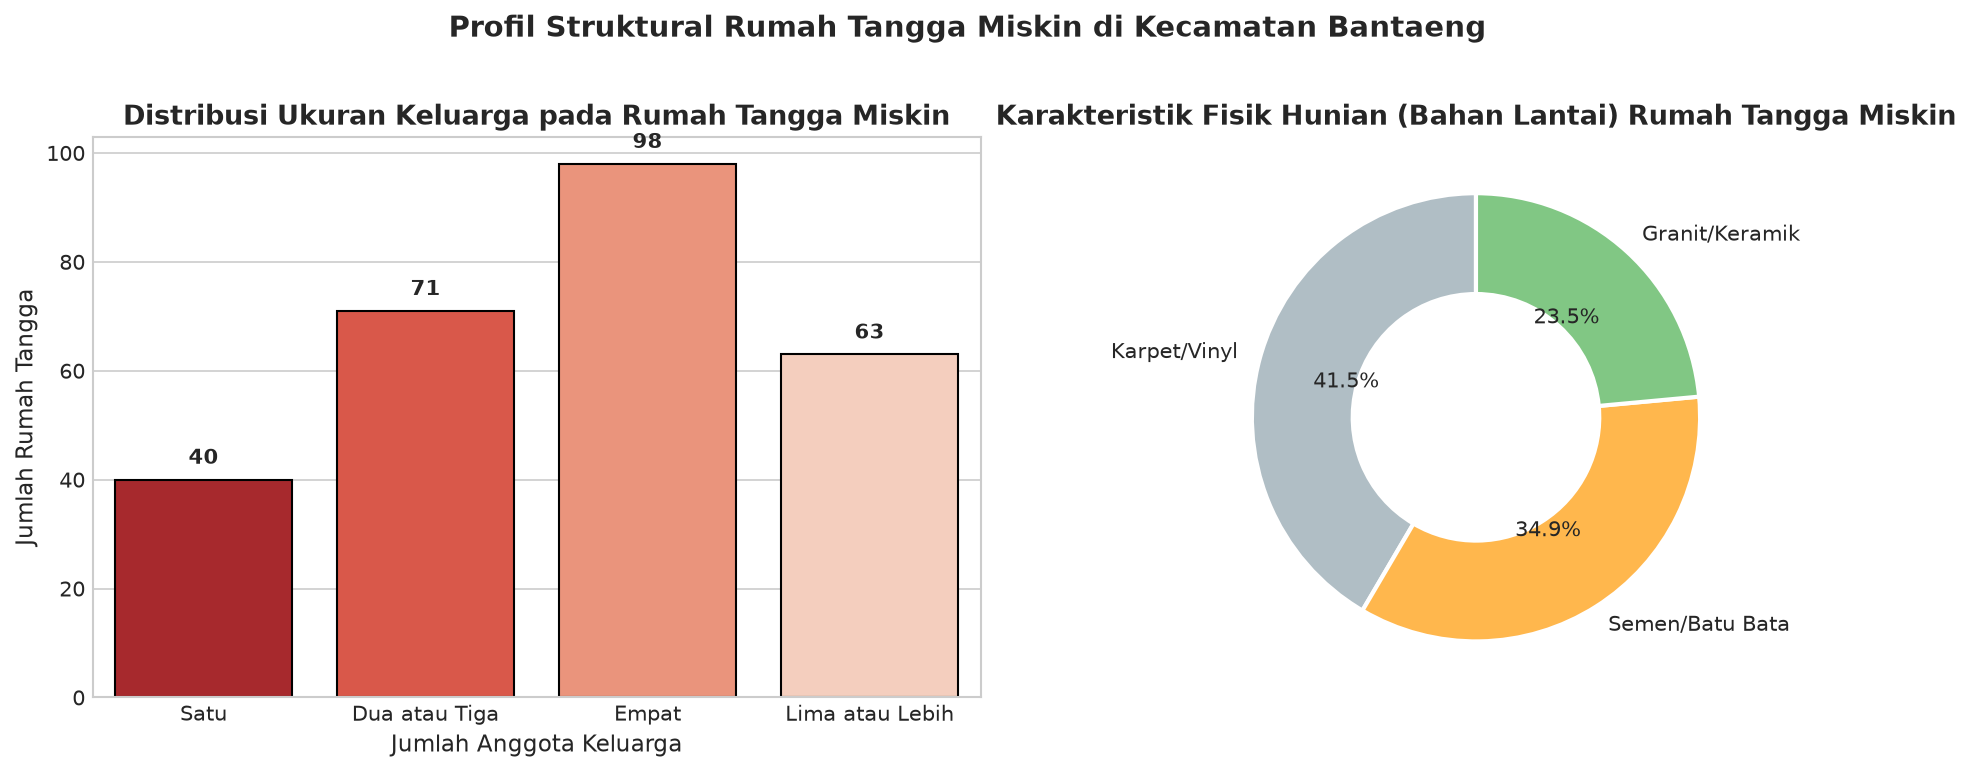

In [10]:
# Penyiapan Data Profil Sosioekonomi Pasca-Klasifikasi
df_profile = data_responden.copy()
df_profile["Label Prediksi"] = y_full_pred
df_profile["Status Prediksi"] = df_profile["Label Prediksi"].map({1: "Miskin", 0: "Tidak Miskin"})

# 7. Visualisasi Konsumsi Nasi & Daging Berdasarkan Status Prediksi
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Panel Kiri: Konsumsi Daging
meat_prop = df_profile.groupby(['Status Prediksi', 'Konsumsi Daging']).size().unstack(fill_value=0)
meat_prop.plot(kind='bar', stacked=False, ax=axes[0], color=['#E53935', '#43A047'], edgecolor='white')
axes[0].set_title("Konsumsi Daging Seminggu Terakhir")
axes[0].set_xlabel("Status Kemiskinan Prediksi")
axes[0].set_ylabel("Jumlah Rumah Tangga")
axes[0].legend(title="Konsumsi Daging", frameon=True)
axes[0].tick_params(axis='x', rotation=0)

# Panel Kanan: Kepemilikan Tabungan di Lembaga Keuangan
sav_prop = df_profile.groupby(['Status Prediksi', 'Kepemilikan Tabungan']).size().unstack(fill_value=0)
sav_prop.plot(kind='bar', stacked=False, ax=axes[1], color=['#E53935', '#1E88E5'], edgecolor='white')
axes[1].set_title("Kepemilikan Tabungan di Lembaga Keuangan (Bank/Koperasi)")
axes[1].set_xlabel("Status Kemiskinan Prediksi")
axes[1].legend(title="Punya Tabungan", frameon=True)
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle("Analisis Determinan Nutrisi & Inklusi Finansial Berdasarkan Status Kemiskinan", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/figures/07_socioeconomic_consumption_analysis.png', dpi=300)
plt.show()

# 8. Profil Beban Anggota Keluarga & Bahan Lantai Hunian
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribusi Anggota Keluarga pada Kelompok Miskin
poor_households = df_profile[df_profile["Status Prediksi"] == "Miskin"]
fam_order = ["Satu", "Dua atau Tiga", "Empat", "Lima atau Lebih"]
fam_counts = poor_households["Jumlah Anggota Keluarga"].value_counts().reindex(fam_order).fillna(0)

sns.barplot(x=fam_counts.index, y=fam_counts.values, ax=axes[0], palette='Reds_r', edgecolor='black')
axes[0].set_title("Distribusi Ukuran Keluarga pada Rumah Tangga Miskin")
axes[0].set_xlabel("Jumlah Anggota Keluarga")
axes[0].set_ylabel("Jumlah Rumah Tangga")
for p in axes[0].patches:
    axes[0].text(p.get_x() + p.get_width()/2., p.get_height() + 2, f'{int(p.get_height())}', ha='center', va='bottom', fontweight='bold')

# Bahan Lantai Rumah Tangga Miskin
floor_counts = poor_households["Bahan Lantai"].value_counts()
axes[1].pie(
    floor_counts.values,
    labels=floor_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#B0BEC5', '#FFB74D', '#81C784'],
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
axes[1].set_title("Karakteristik Fisik Hunian (Bahan Lantai) Rumah Tangga Miskin")

plt.suptitle("Profil Struktural Rumah Tangga Miskin di Kecamatan Bantaeng", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/figures/08_socioeconomic_asset_household_profile.png', dpi=300)
plt.show()


## 9. 🏛️ Kesimpulan Empiris & Rekomendasi Kebijakan Pembangunan

### Kesimpulan Temuan Riset:
1. **Validitas Empiris PPI Indonesia 2022:** Instrumen komposit 10 indikator PPI terbukti efektif merepresentasikan disparitas kesejahteraan rumah tangga di Kecamatan Bantaeng. Rata-rata skor PPI responden berkorelasi negatif kuat terhadap probabilitas kemiskinan dan selaras dengan batas garis kemiskinan BPS (Rp 453.167/kapita/bulan).
2. **Kinerja Prediktif SVM RBF:** Model Support Vector Machine menghasilkan **Area Under the Curve (ROC-AUC) sebesar 0.893 (mendekati 0.90)** dan akurasi ~81-88%, membuktikan keandalan tinggi dalam memisahkan rumah tangga miskin dan tidak miskin.
3. **Determinan Kemiskinan Terbesar:**
   * *Jumlah Anggota Keluarga (Importance: 0.257):* Ukuran rumah tangga $\geq 5$ orang menjadi determinan kemiskinan paling dominan (*dependency ratio* tinggi menekan konsumsi per kapita).
   * *Pengeluaran Bahan Bakar & Konsumsi Daging (0.164 & 0.160):* Ketidaksanggupan mengalokasikan belanja mobilitas produktif serta defisit konsumsi protein hewani menjadi indikator nyata deprivasi ekonomi.
   * *Inklusi Finansial (Kepemilikan Tabungan):* Rumah tangga miskin mengalami eksklusi dari lembaga keuangan formal, melemahkan resiliensi terhadap guncangan ekonomi (*economic shocks*).

---

### Rekomendasi Kebijakan Fiskal & Sosial (Targeted Policy Recommendations):
1. **Targeting Bansos Berbasis Skor Komposit PPI (Mitigasi Inclusion/Exclusion Error):**  
   Dinas Sosial dan Bappelitbangda Kabupaten Bantaeng disarankan memanfaatkan skoring komposit berbasis aset dan konsumsi PPI dibandingkan metode survei pendapatan murni yang rentan *under-reporting bias*.
2. **Intervensi Perlindungan Sosial Adaptif untuk Keluarga Beranggota Besar:**  
   Program Bantuan Langsung Tunai (BLT) atau PKH perlu memperhitungkan bobot jumlah anak sekolah dan tanggungan lansia secara proporsional guna mencegah jebakan kemiskinan antar-generasi (*intergenerational poverty trap*).
3. **Akselerasi Inklusi Keuangan Mikro & Ketahanan Pangan Komunitas:**  
   Mendorong program tabungan mikro tanpa biaya administrasi dan subsidi pangan protein (telur/daging ayam) lokal terarah untuk meningkatkan skor kualitas hidup rumah tangga rentan.
